# Optimizing within clusters before combining them

The spectral condition number compares the largest and smallest eigenvalues of a positive definite covariance matrix:

$$
\kappa_2(\Sigma)=\frac{\lambda_{\max}(\Sigma)}{\lambda_{\min}(\Sigma)}.
$$

Here, $\Sigma$ is a covariance matrix, $\lambda_{\max}(\Sigma)$ and $\lambda_{\min}(\Sigma)$ are its largest and smallest eigenvalues, and $\kappa_2(\Sigma)$ measures how strongly small input changes can be magnified by inversion.

Row,Field,Value
,String,String
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Selected industries,16
7,Selection rule,"First 16 industries in archive order, fixed before analysis"


Row,Case,Assets,Smallest eigenvalue,Largest eigenvalue,Condition number,Mean off-diagonal correlation
,String,Int64,Float64,Float64,Float64,Float64
1,Separated clusters,6,0.00345889,0.0936401,27.0723,0.28
2,Connected clusters,6,0.00345584,0.0992765,28.7272,0.43
3,Public industries,16,0.00576005,0.595064,103.309,0.532016


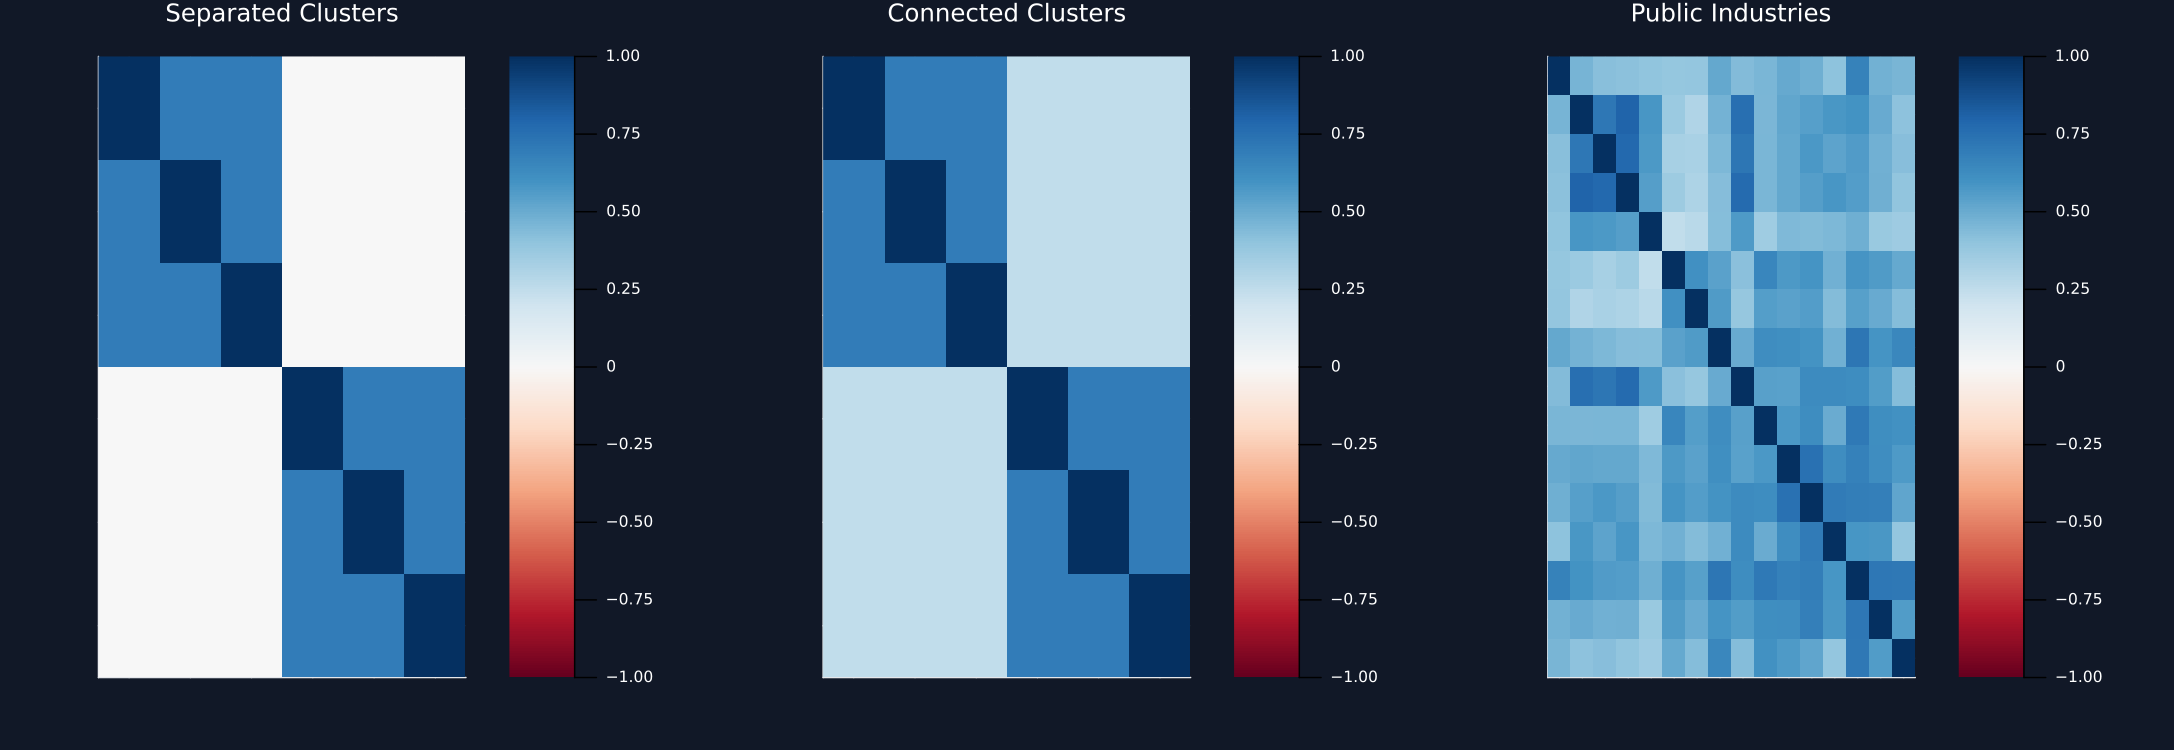

Row,Cluster,Industry,Silhouette value
,Int64,String,Float64
1,1,Beer and liquor,0.339018
2,1,Food products,0.311947
3,1,Household products,0.270148
4,1,Pharmaceutical products,0.0300724
5,1,Soft drinks,0.292816
6,1,Tobacco,0.164483
7,2,Agriculture,0.0777263
8,2,Apparel,0.207026
9,2,Chemicals,0.181523


Row,Cluster,Industries,Mean silhouette value,Minimum silhouette value
,Int64,Int64,Float64,Float64
1,1,6,0.234747,0.0300724
2,2,10,0.16692,0.0777263


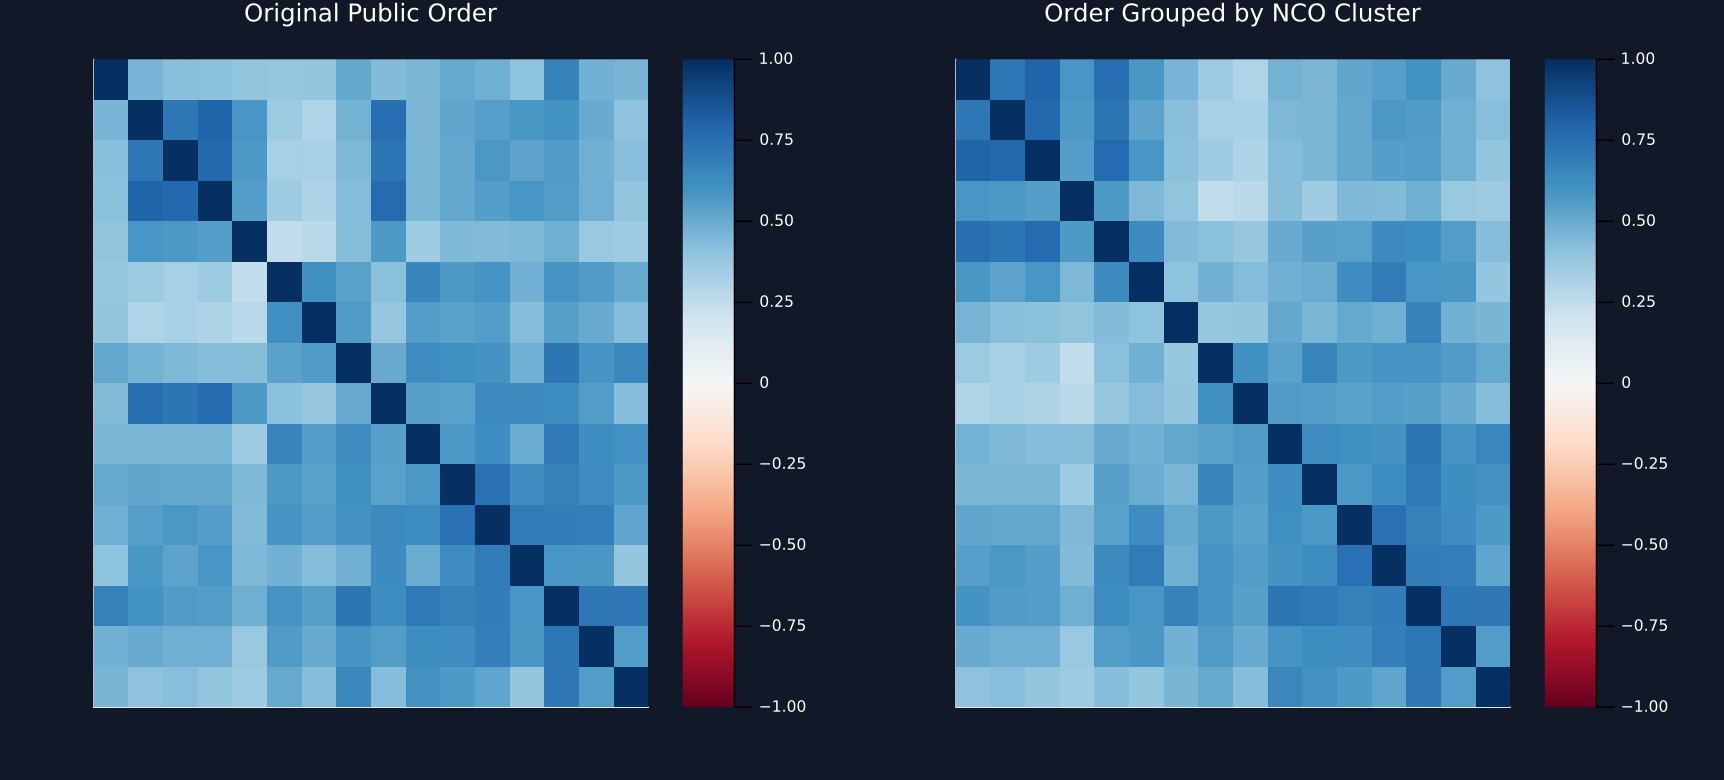

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("26_nested_cluster_optimization");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
function matrix_panel(values,labels,title;limits=nothing,color=:magma)
    n = length(labels)
    return heatmap(1:n,1:n,values;title,color,clims=isnothing(limits) ? extrema(values) : limits,yflip=true,xticks=(1:n,labels),yticks=(1:n,labels),xrotation=90,tickfontsize=7,xlims=(0.5,n+0.5),ylims=(0.5,n+0.5),widen=false)
end
function tree_panel(tree,order,labels,title)
    n = length(labels)
    positions,heights = zeros(2n-1),zeros(2n-1)
    positions[order] = 1:n
    figure = plot(;title,xlim=(0.3,n+0.7),ylim=(0,1.08*maximum(tree[:,3])),xticks=(1:n,labels[order]),xrotation=90,tickfontsize=7,ylabel="Merge distance",legend=false)
    for step in axes(tree,1)
        left,right = Int.(tree[step,1:2]).+1
        height = tree[step,3]
        plot!(figure,[positions[left],positions[left],positions[right],positions[right]],[heights[left],height,height,heights[right]];color=palette.cyan)
        positions[n+step],heights[n+step] = (positions[left]+positions[right])/2,height
    end
    return figure
end
path_length(distance,order) = sum(distance[order[i],order[i+1]] for i in 1:length(order)-1)
turnover(a,b) = 0.5*sum(abs,a-b)
finite_mean(values) = mean(filter(isfinite,values))
include(joinpath("..","support","BookNCO.jl"))
using .BookNCO
using RiskLabAI.Optimization: get_optimal_portfolio_weights
selected_assets = ["Agriculture","Food products","Soft drinks","Beer and liquor","Tobacco","Recreation","Entertainment","Printing and publishing","Household products","Apparel","Health care","Medical equipment","Pharmaceutical products","Chemicals","Rubber and plastic products","Textiles"]
public_covariance = annual_covariance
random_root = joinpath("..","data","chapter26_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
public_provenance = DataFrame("Field"=>["Provider","Return type","Analysis start","Analysis end","Complete dates","Selected industries","Selection rule"],"Value"=>["Kenneth R. French Data Library","Daily value-weighted return",string(first(dates)),string(last(dates)),string(length(dates)),"16","First 16 industries in archive order, fixed before analysis"])
table(public_provenance,"nco_data_provenance","Public data used for the Chapter 22 NCO calculation.")
separated_covariance,separated_correlation = block_covariance(2,3,0.7,0.0)
connected_covariance,connected_correlation = block_covariance(2,3,0.7,0.25)
condition_rows = NamedTuple[]
for (name,covariance,correlation) in [("Separated clusters",separated_covariance,separated_correlation),("Connected clusters",connected_covariance,connected_correlation),("Public industries",public_covariance,public_correlation)]
    values = eigvals(Symmetric(covariance))
    n = size(covariance,1)
    push!(condition_rows,(Case=name,Assets=n,smallest=first(values),largest=last(values),condition=last(values)/first(values),correlation=(sum(correlation)-n)/(n*(n-1))))
end
condition_summary = DataFrame(condition_rows)
rename!(condition_summary,["Case","Assets","Smallest eigenvalue","Largest eigenvalue","Condition number","Mean off-diagonal correlation"])
table(condition_summary,"condition_number_cases","Condition numbers for two controlled covariance structures and the public sample.")
panels = [matrix_panel(matrix,fill("",size(matrix,1)),title;limits=(-1,1),color=:RdBu) for (matrix,title) in [(separated_correlation,"Separated Clusters"),(connected_correlation,"Connected Clusters"),(public_correlation,"Public Industries")]]
save_figure(plot(panels...;layout=(1,3),size=(1450,500)),paths,"condition_number_correlation_cases")
candidate_rows = NamedTuple[]
function record_candidate(step,k,features,fitted)
    append!(candidate_rows,[(step=step,clusters=k,asset=i,label=fitted.labels[i],inertia=fitted.inertia,iterations=fitted.iterations) for i in eachindex(fitted.labels)])
end
public_components = nco_components(public_covariance,primitive("kmeans_2201.csv");trace=record_candidate)
save_data(DataFrame(candidate_rows),paths,"public_candidate_fits")
cluster_rows = [(Cluster=key+1,Industry=selected_assets[asset],silhouette=public_components.silhouette[asset]) for key in public_components.keys_sorted for asset in public_components.clusters[key]]
cluster_membership = sort(DataFrame(cluster_rows),[:Cluster,:Industry])
rename!(cluster_membership,:silhouette=>"Silhouette value")
cluster_summary = combine(groupby(cluster_membership,:Cluster;sort=true),nrow=>"Industries","Silhouette value"=>mean=>"Mean silhouette value","Silhouette value"=>minimum=>"Minimum silhouette value")
table(cluster_membership,"public_cluster_membership","Deterministic public-industry cluster membership.")
table(cluster_summary,"public_cluster_summary","Public-industry cluster sizes and silhouette values.")
ordered_assets = reduce(vcat,[public_components.clusters[key] for key in public_components.keys_sorted])
p1 = matrix_panel(public_correlation,fill("",16),"Original Public Order";limits=(-1,1),color=:RdBu)
p2 = matrix_panel(public_correlation[ordered_assets,ordered_assets],fill("",16),"Order Grouped by NCO Cluster";limits=(-1,1),color=:RdBu)
save_figure(plot(p1,p2;layout=(1,2),size=(1150,520)),paths,"public_nco_cluster_structure")
save_data(DataFrame(public_covariance,:auto),paths,"public_covariance")
save_data(DataFrame(public_correlation,:auto),paths,"public_correlation")
nothing


## Within-Cluster Portfolios

Within cluster $g$, the fully invested optimization direction is normalized to give local weights:

$$
v_g=\frac{\Sigma_{gg}^{-1}m_g}{\mathbf 1_g^{\mathsf T}\Sigma_{gg}^{-1}m_g}.
$$

Here, $g$ labels a cluster, $\Sigma_{gg}$ is its covariance block, $m_g$ is a vector of ones for minimum variance or a vector of expected returns for a return-directed portfolio, $\mathbf 1_g$ is a vector of ones, and $v_g$ is the cluster's local weight vector.

Row,Cluster,Industry,Within-cluster weight,Cluster variance
,Int64,String,Float64,Float64
1,1,Beer and liquor,-0.181577,0.0232679
2,1,Food products,0.506141,0.0232679
3,1,Household products,0.111383,0.0232679
4,1,Pharmaceutical products,0.318581,0.0232679
5,1,Soft drinks,0.167242,0.0232679
6,1,Tobacco,0.0782306,0.0232679
7,2,Agriculture,0.131588,0.0383078
8,2,Apparel,-0.0180391,0.0383078
9,2,Chemicals,0.040779,0.0383078


Row,Cluster,Industries,Weight sum,Smallest weight,Largest weight,Cluster variance
,Int64,Int64,Float64,Float64,Float64,Float64
1,1,6,1.0,-0.181577,0.506141,0.0232679
2,2,10,1.0,-0.141539,0.354479,0.0383078


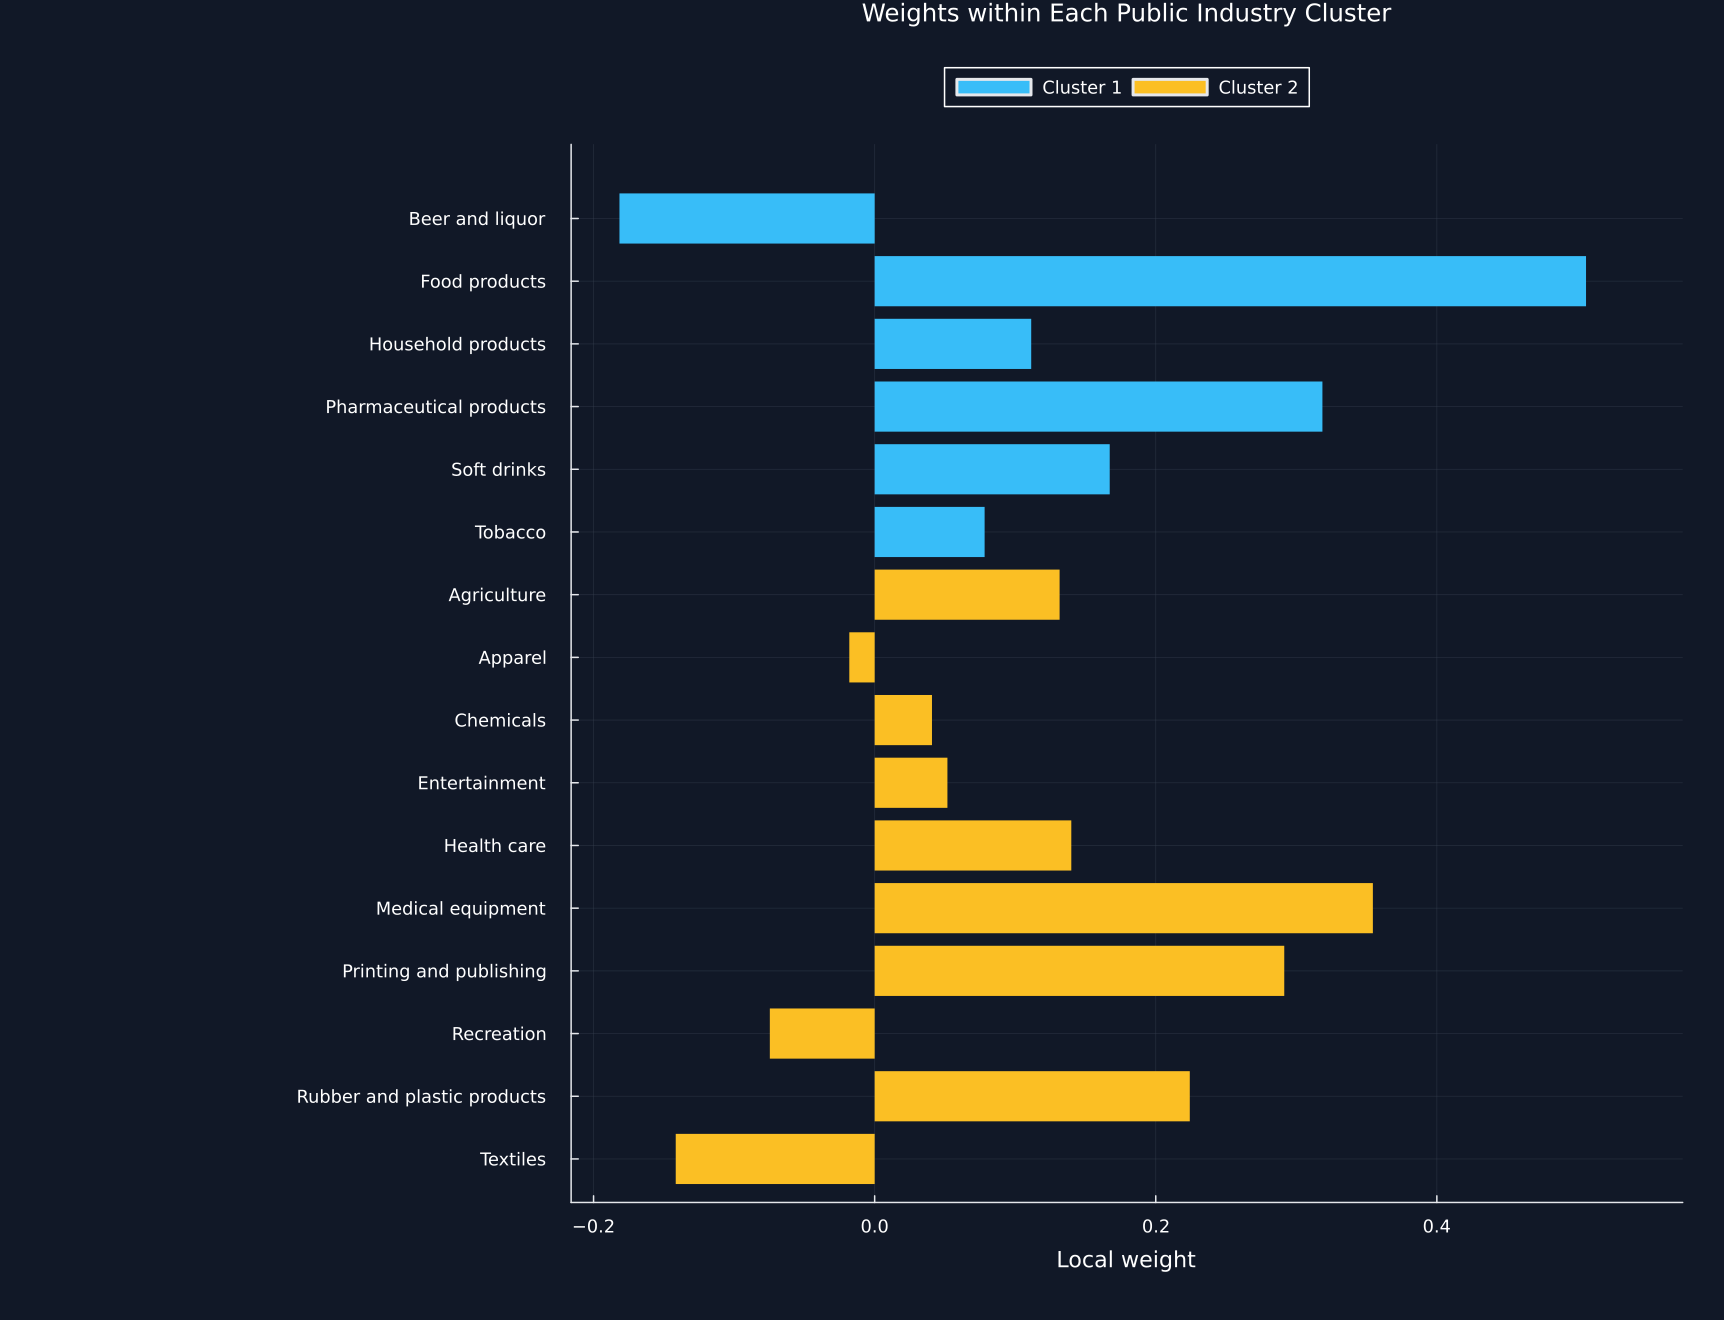

In [2]:
within_rows = NamedTuple[]
for (column,key) in enumerate(public_components.keys_sorted)
    members = public_components.clusters[key]
    local_weights = public_components.within[members,column]
    variance = dot(local_weights,public_covariance[members,members]*local_weights)
    append!(within_rows,[(Cluster=key+1,Industry=selected_assets[asset],weight=public_components.within[asset,column],variance=variance) for asset in members])
end
within_weights = sort(DataFrame(within_rows),[:Cluster,:Industry])
rename!(within_weights,["Cluster","Industry","Within-cluster weight","Cluster variance"])
within_checks = combine(groupby(within_weights,:Cluster;sort=true),nrow=>"Industries","Within-cluster weight"=>sum=>"Weight sum","Within-cluster weight"=>minimum=>"Smallest weight","Within-cluster weight"=>maximum=>"Largest weight","Cluster variance"=>first=>"Cluster variance")
table(within_weights,"within_cluster_weights","Public within-cluster minimum-variance weights.")
table(within_checks,"within_cluster_checks","Within-cluster normalization and risk checks.")
colors = [palette.cyan,palette.amber,palette.green,violet]
figure = plot(;title="Weights within Each Public Industry Cluster",xlabel="Local weight",yticks=(1:16,within_weights.Industry),yflip=true,legend=:outertop,legend_columns=2,left_margin=49Plots.mm,size=(1150,880))
for cluster in unique(within_weights.Cluster)
    positions = findall(==(cluster),within_weights.Cluster)
    bar!(figure,positions,within_weights[positions,"Within-cluster weight"];orientation=:h,color=colors[cluster],linealpha=0,label="Cluster "*string(cluster))
end
lo,hi = extrema(within_weights[!,"Within-cluster weight"])
plot!(figure;xlims=(min(0,lo)-0.05*(hi-lo),hi+0.1*(hi-lo)))
save_figure(figure,paths,"within_cluster_weight_profiles")


## The Reduced Cluster Problem

Placing the local cluster portfolios in the columns of $B$ reduces the asset covariance matrix to a cluster covariance matrix:

$$
\Sigma_C=B^{\mathsf T}\Sigma B.
$$

Here, $B$ is the matrix of within-cluster weights with zeros outside each cluster, $\Sigma$ is the full asset covariance matrix, and $\Sigma_C$ is the covariance matrix of the cluster portfolios.

Row,Cluster portfolio,Cluster 1,Cluster 2
,String,Float64,Float64
1,Cluster 1,0.0232679,0.0218979
2,Cluster 2,0.0218979,0.0383078


Row,Quantity,Value
,String,Float64
1,Asset covariance dimension,16.0
2,Reduced covariance dimension,2.0
3,Asset condition number,103.309
4,Reduced condition number,7.06521
5,Smallest reduced eigenvalue,0.00763474
6,Largest reduced eigenvalue,0.053941


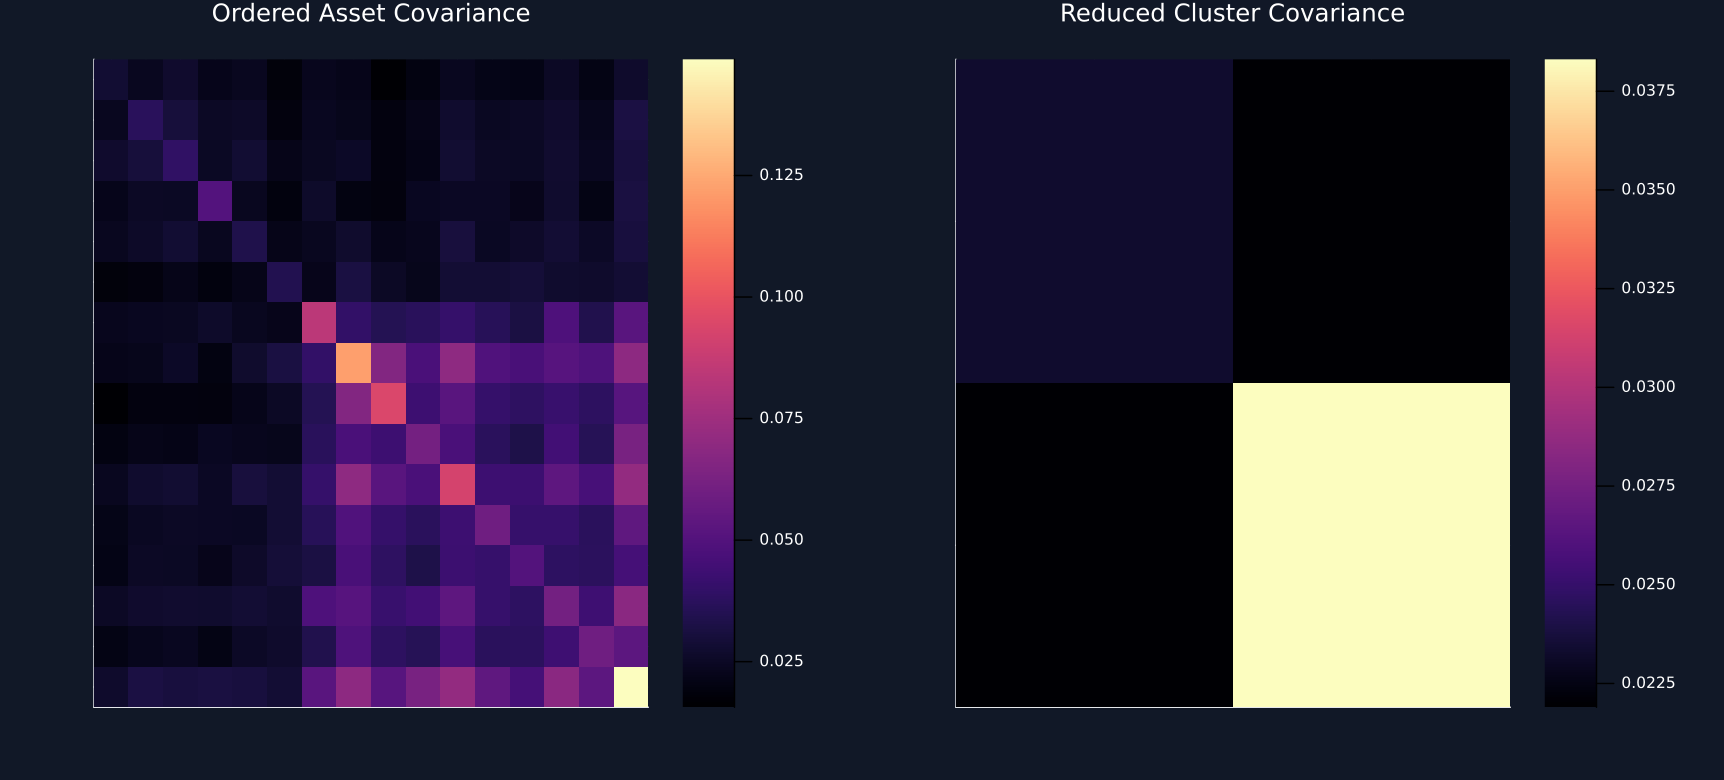

In [3]:
reduced_covariance = public_components.reduced_covariance
cluster_names = ["Cluster "*string(key+1) for key in public_components.keys_sorted]
reduced_table = hcat(DataFrame("Cluster portfolio"=>cluster_names),DataFrame(reduced_covariance,cluster_names))
reduced_eigenvalues = eigvals(Symmetric(reduced_covariance))
reduced_summary = DataFrame("Quantity"=>["Asset covariance dimension","Reduced covariance dimension","Asset condition number","Reduced condition number","Smallest reduced eigenvalue","Largest reduced eigenvalue"],"Value"=>[16,size(reduced_covariance,1),cond(public_covariance),cond(reduced_covariance),first(reduced_eigenvalues),last(reduced_eigenvalues)])
table(reduced_table,"reduced_cluster_covariance","Covariance matrix of the public cluster portfolios.")
table(reduced_summary,"reduced_problem_summary","Dimensions and condition numbers before and after reduction.")
p1 = matrix_panel(public_covariance[ordered_assets,ordered_assets],fill("",16),"Ordered Asset Covariance")
p2 = matrix_panel(reduced_covariance,fill("",length(cluster_names)),"Reduced Cluster Covariance")
save_figure(plot(p1,p2;layout=(1,2),size=(1150,520)),paths,"asset_and_reduced_covariance")


## Recombining cluster portfolios

The cluster portfolios are optimized and then mapped back to the original assets:

$$
a=\frac{\Sigma_C^{-1}m_C}{\mathbf 1_C^{\mathsf T}\Sigma_C^{-1}m_C},
\qquad
w^{\mathrm{NCO}}=Ba.
$$

Here, $a$ contains between-cluster weights, $m_C=B^{\mathsf T}m$ is the reduced return direction or a vector of ones in the minimum-variance case, $\mathbf 1_C$ is a vector of ones over clusters, and $w^{\mathrm{NCO}}$ contains the final asset weights.

Row,Cluster,Between-cluster weight
,String,Float64
1,Cluster 1,0.922945
2,Cluster 2,0.0770551


Row,Industry,NCO weight,Cluster
,String,Float64,Int64
1,Agriculture,0.0101395,2
2,Apparel,-0.00139001,2
3,Beer and liquor,-0.167586,1
4,Chemicals,0.00314223,2
5,Entertainment,0.00398912,2
6,Food products,0.46714,1
7,Health care,0.0107806,2
8,Household products,0.1028,1
9,Medical equipment,0.0273144,2


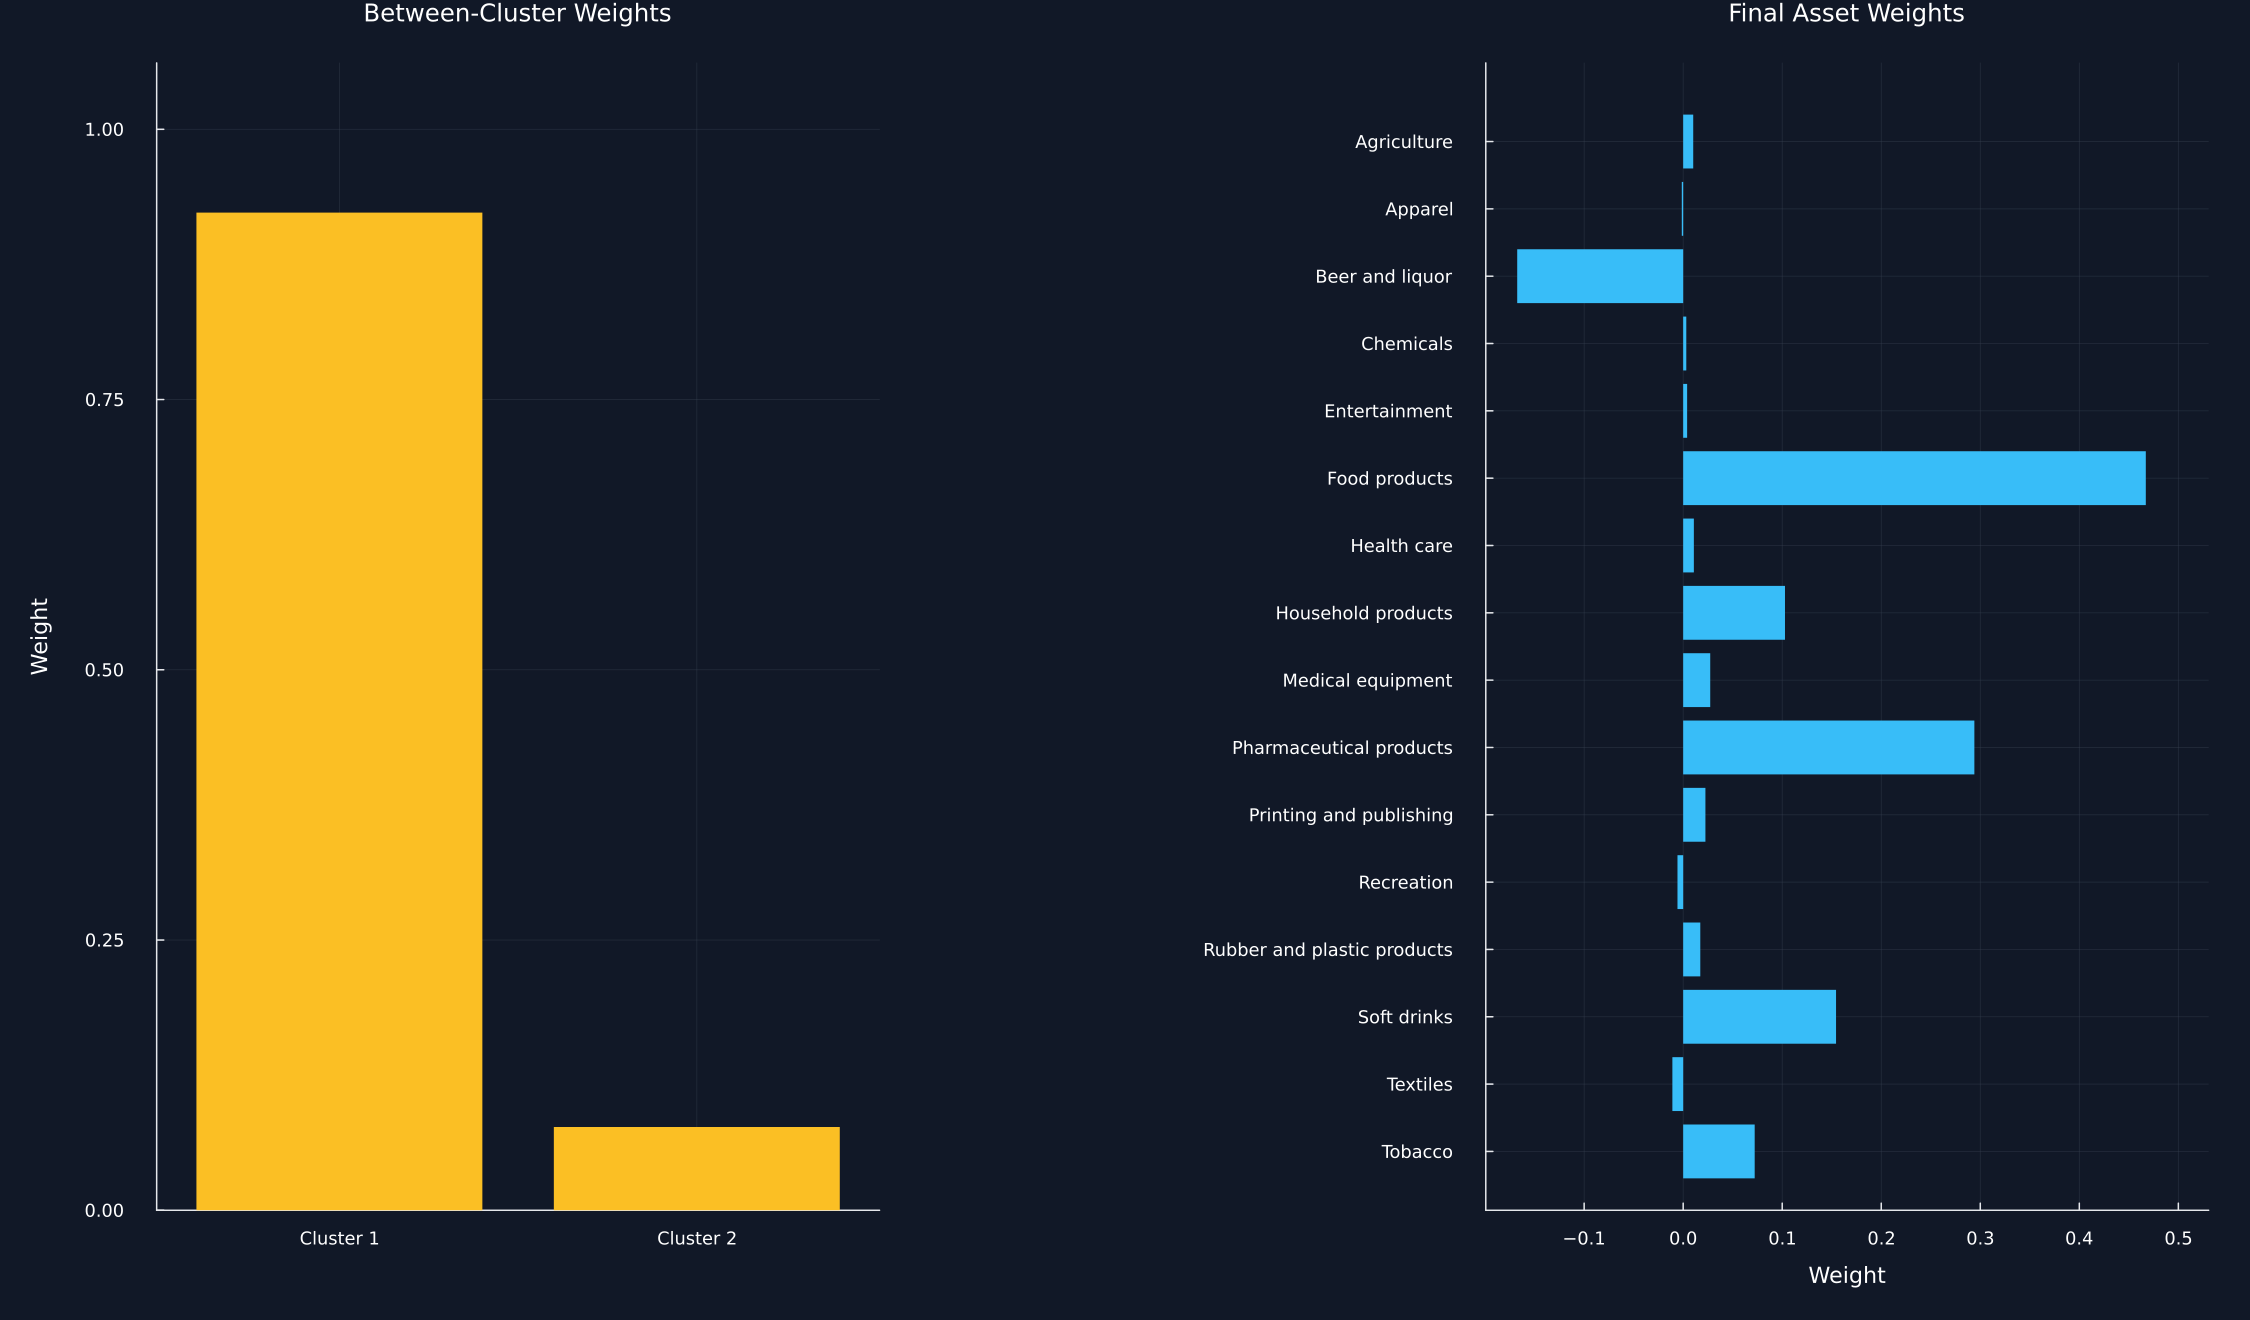

In [4]:
between_table = DataFrame("Cluster"=>cluster_names,"Between-cluster weight"=>public_components.between)
final_order = sortperm(selected_assets)
labels = zeros(Int,16)
for (key,members) in public_components.clusters
    labels[members] .= key+1
end
final_table = DataFrame("Industry"=>selected_assets[final_order],"NCO weight"=>public_components.final[final_order],"Cluster"=>labels[final_order])
table(between_table,"between_cluster_weights","Weights assigned to the public cluster portfolios.")
table(final_table,"public_nco_weights","Final public-industry NCO weights.")
p1 = bar(1:length(cluster_names),public_components.between;color=palette.amber,linealpha=0,legend=false,xticks=(1:length(cluster_names),cluster_names),title="Between-Cluster Weights",ylabel="Weight",ylims=(min(0,minimum(public_components.between))*1.1,maximum(public_components.between)*1.15))
lo,hi = extrema(public_components.final)
p2 = bar(1:16,public_components.final[final_order];orientation=:h,yflip=true,yticks=(1:16,selected_assets[final_order]),color=palette.cyan,linealpha=0,legend=false,title="Final Asset Weights",xlabel="Weight",left_margin=47Plots.mm,xlims=(min(0,lo)-0.05*(hi-lo),hi+0.1*(hi-lo)))
save_figure(plot(p1,p2;layout=(1,2),size=(1500,880)),paths,"between_and_final_nco_weights")


## Released Calculation Checks

The reduced covariance preserves the variance of every weight vector formed from the cluster portfolios:

$$
(Ba)^{\mathsf T}\Sigma(Ba)=a^{\mathsf T}(B^{\mathsf T}\Sigma B)a=a^{\mathsf T}\Sigma_Ca.
$$

Here, $B$ contains within-cluster weights, $a$ contains between-cluster weights, $\Sigma$ is the full covariance matrix, and $\Sigma_C$ is the reduced covariance matrix.

In [5]:
released_weights = public_components.released
direct_variance = dot(public_components.final,public_covariance*public_components.final)
reduced_variance = dot(public_components.between,reduced_covariance*public_components.between)
comparison = DataFrame("Industry"=>selected_assets,"Direct two-stage weight"=>public_components.final,"Library NCO weight"=>released_weights,"Absolute difference"=>abs.(public_components.final-released_weights))
calculation_checks = DataFrame("Check"=>["Directly assembled weights sum to one","Library weights sum to one","Largest direct and library weight difference","Full variance","Reduced variance","Absolute variance difference"],"Value"=>[sum(public_components.final),sum(released_weights),maximum(comparison[!,4]),direct_variance,reduced_variance,abs(direct_variance-reduced_variance)])
ivp = inverse_variance_weights(public_covariance)
portfolios = ["NCO"=>released_weights,"Ordinary minimum variance"=>get_optimal_portfolio_weights(public_covariance),"Inverse variance"=>ivp,"Equal weight"=>fill(1/16,16)]
public_portfolio_summary = DataFrame([(Portfolio=name,volatility=sqrt(dot(weights,public_covariance*weights)),net=sum(weights),gross=sum(abs,weights),smallest=minimum(weights),largest=maximum(weights)) for (name,weights) in portfolios])
rename!(public_portfolio_summary,["Portfolio","Annual volatility","Net exposure","Gross exposure","Smallest weight","Largest weight"])
k = length(public_components.clusters)
section_summary = DataFrame("Quantity"=>["Public observations","Selected industries","Detected clusters","Within-cluster portfolios","Reduced covariance dimension","Final weights"],"Value"=>[length(dates),16,k,k,k,16])
table(comparison,"released_nco_weight_check","Directly assembled and library NCO weights for the public covariance matrix.")
table(calculation_checks,"nco_calculation_checks","Direct checks of the two-stage NCO calculation.")
table(public_portfolio_summary,"public_nco_portfolio_summary","Public-sample fitted portfolio summaries.")
table(section_summary,"nco_section_summary","Section 22.1 numerical summary.")


Row,Industry,Direct two-stage weight,Library NCO weight,Absolute difference
,String,Float64,Float64,Float64
1,Agriculture,0.0101395,0.0101395,0.0
2,Food products,0.46714,0.46714,0.0
3,Soft drinks,0.154355,0.154355,0.0
4,Beer and liquor,-0.167586,-0.167586,0.0
5,Tobacco,0.0722025,0.0722025,0.0
6,Recreation,-0.00574731,-0.00574731,0.0
7,Entertainment,0.00398912,0.00398912,0.0
8,Printing and publishing,0.0224562,0.0224562,0.0
9,Household products,0.1028,0.1028,0.0


Row,Check,Value
,String,Float64
1,Directly assembled weights sum to one,1.0
2,Library weights sum to one,1.0
3,Largest direct and library weight difference,0.0
4,Full variance,0.0231624
5,Reduced variance,0.0231624
6,Absolute variance difference,0.0


Row,Portfolio,Annual volatility,Net exposure,Gross exposure,Smallest weight,Largest weight
,String,Float64,Float64,Float64,Float64,Float64
1,NCO,0.152192,1.0,1.37126,-0.167586,0.46714
2,Ordinary minimum variance,0.147925,1.0,1.95891,-0.167604,0.489942
3,Inverse variance,0.169625,1.0,1.0,0.022161,0.118033
4,Equal weight,0.185824,1.0,1.0,0.0625,0.0625


Row,Quantity,Value
,String,Int64
1,Public observations,1760
2,Selected industries,16
3,Detected clusters,2
4,Within-cluster portfolios,2
5,Reduced covariance dimension,2
6,Final weights,16


## Tests

In [6]:
@assert size(public_sample)==(1760,16)
@assert all(eigvals(Symmetric(separated_covariance)).>0)
@assert all(eigvals(Symmetric(connected_covariance)).>0)
@assert nrow(condition_summary)==3
@assert all(condition_summary[!,5].>1)
@assert 2<=length(public_components.clusters)<=4
@assert sort(cluster_membership.Industry)==sort(selected_assets)
@assert all(-1 .<=cluster_membership[!,3].<=1)
@assert within_checks[!,"Weight sum"]≈ones(k)
@assert size(public_components.within)==(16,k)
@assert size(reduced_covariance)==(k,k)
@assert reduced_covariance≈reduced_covariance'
@assert minimum(reduced_eigenvalues)>0
@assert sum(public_components.between)≈1
@assert sum(public_components.final)≈1
@assert sum(released_weights)≈1
@assert maximum(comparison[!,4])<1e-12
@assert abs(direct_variance-reduced_variance)<1e-12
@assert nrow(public_portfolio_summary)==4
@assert all(public_portfolio_summary[!,2].>0)
@assert nrow(section_summary)==6
@assert isfile(joinpath(paths.figures,"condition_number_correlation_cases.pdf"))
@assert isfile(joinpath(paths.figures,"public_nco_cluster_structure.pdf"))
@assert isfile(joinpath(paths.figures,"within_cluster_weight_profiles.pdf"))
@assert isfile(joinpath(paths.figures,"asset_and_reduced_covariance.pdf"))
@assert isfile(joinpath(paths.figures,"between_and_final_nco_weights.pdf"))
@assert isfile(joinpath(paths.tables,"released_nco_weight_check.tex"))
@assert isfile(joinpath(paths.tables,"public_nco_portfolio_summary.tex"))
